In [2]:
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier

In [3]:
#opening the file
with open("pokemon_data.json", "r") as file:
    data = json.load(file)

data_df = pd.DataFrame(data)

#dropping unncessary columns and only keeping base stats for the tree
stats = data_df.drop(columns=["name", "types", "base_stat_total"])

#multi label binarizer converts the types into binary data so the model can use it
mlb = MultiLabelBinarizer()
targets = mlb.fit_transform(data_df["types"])

print("Stats:", stats.columns.tolist())
print("Types:", mlb.classes_)

Stats: ['weight', 'height', 'hp', 'attack', 'defense', 'special-attack', 'special-defense', 'speed']
Types: ['bug' 'dark' 'dragon' 'electric' 'fairy' 'fighting' 'fire' 'flying'
 'ghost' 'grass' 'ground' 'ice' 'normal' 'poison' 'psychic' 'rock' 'steel'
 'water']


In [4]:
#splitting data into a 70/15/15 split
x_train, x_test, t_train, t_test = train_test_split(stats, targets, test_size = 0.15, random_state=523)

x_train, x_valid, t_train, t_valid = train_test_split(x_train, t_train, test_size = (0.15 / 0.85), random_state=523)

In [5]:
# determining most optimate number of estimators
estimators = [50, 100, 125, 150, 175, 200, 225, 250]
macro_score = []
for n in estimators:
    tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = n, random_state = 304))
    tree.fit(x_train, t_train)
    validation_prediction = tree.predict(x_valid)
    macro = f1_score(t_valid, validation_prediction, average="macro")
    # print("Macro F1:", macro)
    macro_score.append(macro)


In [6]:
for n in range(len(estimators)):
    print("Estimators: ", estimators[n])
    print("Macro F1: ", macro_score[n])

Estimators:  50
Macro F1:  0.1628213959509999
Estimators:  100
Macro F1:  0.16260957609898435
Estimators:  125
Macro F1:  0.18140105453098562
Estimators:  150
Macro F1:  0.175921048908665
Estimators:  175
Macro F1:  0.18188050339753126
Estimators:  200
Macro F1:  0.18164155477148586
Estimators:  225
Macro F1:  0.18079980392973502
Estimators:  250
Macro F1:  0.18188050339753126


In [7]:
#determining most optimal max depth
estimators2 = [50, 100, 125, 150, 175, 200, 225, 250]
macro_score2 = []
for n in list(range(1, 25)):
    tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = 175, max_depth = n, random_state = 304))
    tree.fit(x_train, t_train)
    validation_prediction = tree.predict(x_valid)
    macro = f1_score(t_valid, validation_prediction, average="macro")
    # print("Macro F1:", macro)
    macro_score2.append(macro)

In [8]:
count = 1
for n in range(24):
    print("Depth: ", count)
    print("Macro F1 score: ", macro_score2[n])
    count+= 1

Depth:  1
Macro F1 score:  0.0
Depth:  2
Macro F1 score:  0.0
Depth:  3
Macro F1 score:  0.017195767195767195
Depth:  4
Macro F1 score:  0.024501424501424503
Depth:  5
Macro F1 score:  0.05098039215686275
Depth:  6
Macro F1 score:  0.06764705882352941
Depth:  7
Macro F1 score:  0.0794753086419753
Depth:  8
Macro F1 score:  0.09331728012842563
Depth:  9
Macro F1 score:  0.13089843344745308
Depth:  10
Macro F1 score:  0.1412158937649134
Depth:  11
Macro F1 score:  0.1437614551993637
Depth:  12
Macro F1 score:  0.15805054492704992
Depth:  13
Macro F1 score:  0.17584889883651492
Depth:  14
Macro F1 score:  0.1656239446573124
Depth:  15
Macro F1 score:  0.1764169769908
Depth:  16
Macro F1 score:  0.1753197983074144
Depth:  17
Macro F1 score:  0.18188050339753126
Depth:  18
Macro F1 score:  0.18188050339753126
Depth:  19
Macro F1 score:  0.18188050339753126
Depth:  20
Macro F1 score:  0.18188050339753126
Depth:  21
Macro F1 score:  0.18188050339753126
Depth:  22
Macro F1 score:  0.1818805033

In [ ]:
#determining most optimal minimum leaf samples
estimators2 = [1, 2, 3, 4, 5, 6, 8, 10, 12]
macro_score2 = []
for n in estimators2:
    tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = 175, max_depth = 17, min_samples_leaf = n, random_state = 304))
    tree.fit(x_train, t_train)
    validation_prediction = tree.predict(x_valid)
    macro = f1_score(t_valid, validation_prediction, average="macro")
    macro_score2.append(macro)

In [ ]:
for n in range(len(estimators2)):
    print("Min leaf samples: ", estimators2[n])
    print("Macro F1 score: ", macro_score2[n])

Min leaf samples:  1
Macro F1 score:  0.18188050339753126
Min leaf samples:  2
Macro F1 score:  0.12083510544036861
Min leaf samples:  3
Macro F1 score:  0.07130454340980658
Min leaf samples:  4
Macro F1 score:  0.048202614379084976
Min leaf samples:  5
Macro F1 score:  0.033916900093370686
Min leaf samples:  6
Macro F1 score:  0.02928727046374106
Min leaf samples:  8
Macro F1 score:  0.02135076252723312
Min leaf samples:  10
Macro F1 score:  0.014472455648926238
Min leaf samples:  12
Macro F1 score:  0.0


In [28]:
#determining most optimal minimum sample split
estimators2 = [2, 4, 6, 8, 10, 15, 20, 25]
macro_score2 = []
for n in estimators2:
    tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = 175, max_depth = 17, min_samples_leaf = 1, min_samples_split = n, random_state = 304))
    tree.fit(x_train, t_train)
    validation_prediction = tree.predict(x_valid)
    macro = f1_score(t_valid, validation_prediction, average="macro")
    macro_score2.append(macro)

In [30]:
for n in range(len(estimators2)):
    print("Min sample split: ", estimators2[n])
    print("Macro F1 score: ", macro_score2[n])

Min sample split:  2
Macro F1 score:  0.18188050339753126
Min sample split:  4
Macro F1 score:  0.14826870722746313
Min sample split:  6
Macro F1 score:  0.11901539818206484
Min sample split:  8
Macro F1 score:  0.08090102707749766
Min sample split:  10
Macro F1 score:  0.0750746167412834
Min sample split:  15
Macro F1 score:  0.03880070546737214
Min sample split:  20
Macro F1 score:  0.033916900093370686
Min sample split:  25
Macro F1 score:  0.02928727046374106


In [31]:
tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = 175, max_depth = 17, min_samples_leaf = 1, min_samples_split = 2, random_state = 304))
tree.fit(x_train, t_train)
validation_prediction = tree.predict(x_valid)
print(classification_report(t_valid, validation_prediction, target_names=mlb.classes_, zero_division = 0))
print("Macro F1:", f1_score(t_valid, validation_prediction, average="macro"))

              precision    recall  f1-score   support

         bug       0.00      0.00      0.00        13
        dark       0.33      0.25      0.29         4
      dragon       0.00      0.00      0.00         7
    electric       0.75      0.23      0.35        13
       fairy       0.80      0.36      0.50        11
    fighting       0.00      0.00      0.00         9
        fire       0.00      0.00      0.00        15
      flying       1.00      0.31      0.47        13
       ghost       0.50      0.11      0.18         9
       grass       0.50      0.05      0.10        19
      ground       0.50      0.07      0.12        15
         ice       0.00      0.00      0.00         6
      normal       1.00      0.22      0.36        23
      poison       0.00      0.00      0.00         7
     psychic       1.00      0.05      0.10        19
        rock       1.00      0.19      0.32        16
       steel       1.00      0.22      0.36         9
       water       0.50    

In [ ]:
#testing predict_proba thresholds to see if it's better
estimators2 = [0.2, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3]
for n in estimators2:
    tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = 175, max_depth = 17, min_samples_leaf = 1, min_samples_split = 2, random_state = 304))
    tree.fit(x_train, t_train)
    validation_prediction = tree.predict_proba(x_valid)
    predictions = (validation_prediction >= n).astype(int)
    # print(classification_report(t_valid, predictions, target_names=mlb.classes_, zero_division = 0))
    print("threshold: ", n)
    print("Macro F1:", f1_score(t_valid, predictions, average="macro"))

threshold:  0.2
Macro F1: 0.2953023236300939
threshold:  0.21
Macro F1: 0.3068634448761843
threshold:  0.22
Macro F1: 0.3046275087070811
threshold:  0.23
Macro F1: 0.30746714034554334
threshold:  0.24
Macro F1: 0.3105185802592769
threshold:  0.25
Macro F1: 0.3076960709064723
threshold:  0.26
Macro F1: 0.3068198305747533
threshold:  0.27
Macro F1: 0.304582790259109
threshold:  0.28
Macro F1: 0.30581044181393674
threshold:  0.29
Macro F1: 0.30629740716532006
threshold:  0.3
Macro F1: 0.31020309781474736


In [ ]:
#visualizing actual types vs predicted types
probabilities = tree.predict_proba(x_valid)

predictions = (probabilities >= 0.24).astype(int)

predicted_types = mlb.inverse_transform(predictions)

for n in range(10):
    print("Actual:", mlb.inverse_transform(t_valid[n:n+1])[0])
    print("Predicted:", predicted_types[n], "\n")

Actual: ('dragon',)
Predicted: ('fighting',) 

Actual: ('ground', 'rock')
Predicted: ('ground', 'rock') 

Actual: ('ghost', 'grass')
Predicted: ('fairy', 'flying', 'grass', 'steel') 

Actual: ('normal',)
Predicted: ('normal',) 

Actual: ('fairy', 'psychic')
Predicted: ('grass', 'normal', 'psychic') 

Actual: ('grass', 'ice')
Predicted: () 

Actual: ('water',)
Predicted: ('grass',) 

Actual: ('bug', 'ground')
Predicted: ('bug', 'grass', 'steel') 

Actual: ('electric', 'rock')
Predicted: ('ground', 'rock') 

Actual: ('fire', 'rock')
Predicted: ('fire',) 



In [ ]:
#running on test set
tree = OneVsRestClassifier(RandomForestClassifier(n_estimators = 175, max_depth = 17, min_samples_leaf = 1, min_samples_split = 2, random_state = 304))
tree.fit(x_train, t_train)
test_prediction = tree.predict_proba(x_test)
predictions = (test_prediction >= 0.24).astype(int)
print(classification_report(t_test, predictions, target_names=mlb.classes_, zero_division = 0))
print("Macro F1:", f1_score(t_test, predictions, average="macro"))

              precision    recall  f1-score   support

         bug       0.11      0.08      0.10        12
        dark       0.00      0.00      0.00        13
      dragon       0.00      0.00      0.00         9
    electric       0.20      0.12      0.15         8
       fairy       0.25      0.18      0.21        11
    fighting       0.15      0.40      0.22         5
        fire       0.33      0.33      0.33         9
      flying       0.58      0.55      0.56        20
       ghost       0.50      0.55      0.52        11
       grass       0.21      0.32      0.25        19
      ground       0.11      0.11      0.11         9
         ice       0.17      0.17      0.17         6
      normal       0.35      0.31      0.33        26
      poison       0.20      0.15      0.17        13
     psychic       0.31      0.22      0.26        18
        rock       0.28      0.45      0.34        11
       steel       0.45      0.45      0.45        11
       water       0.44    

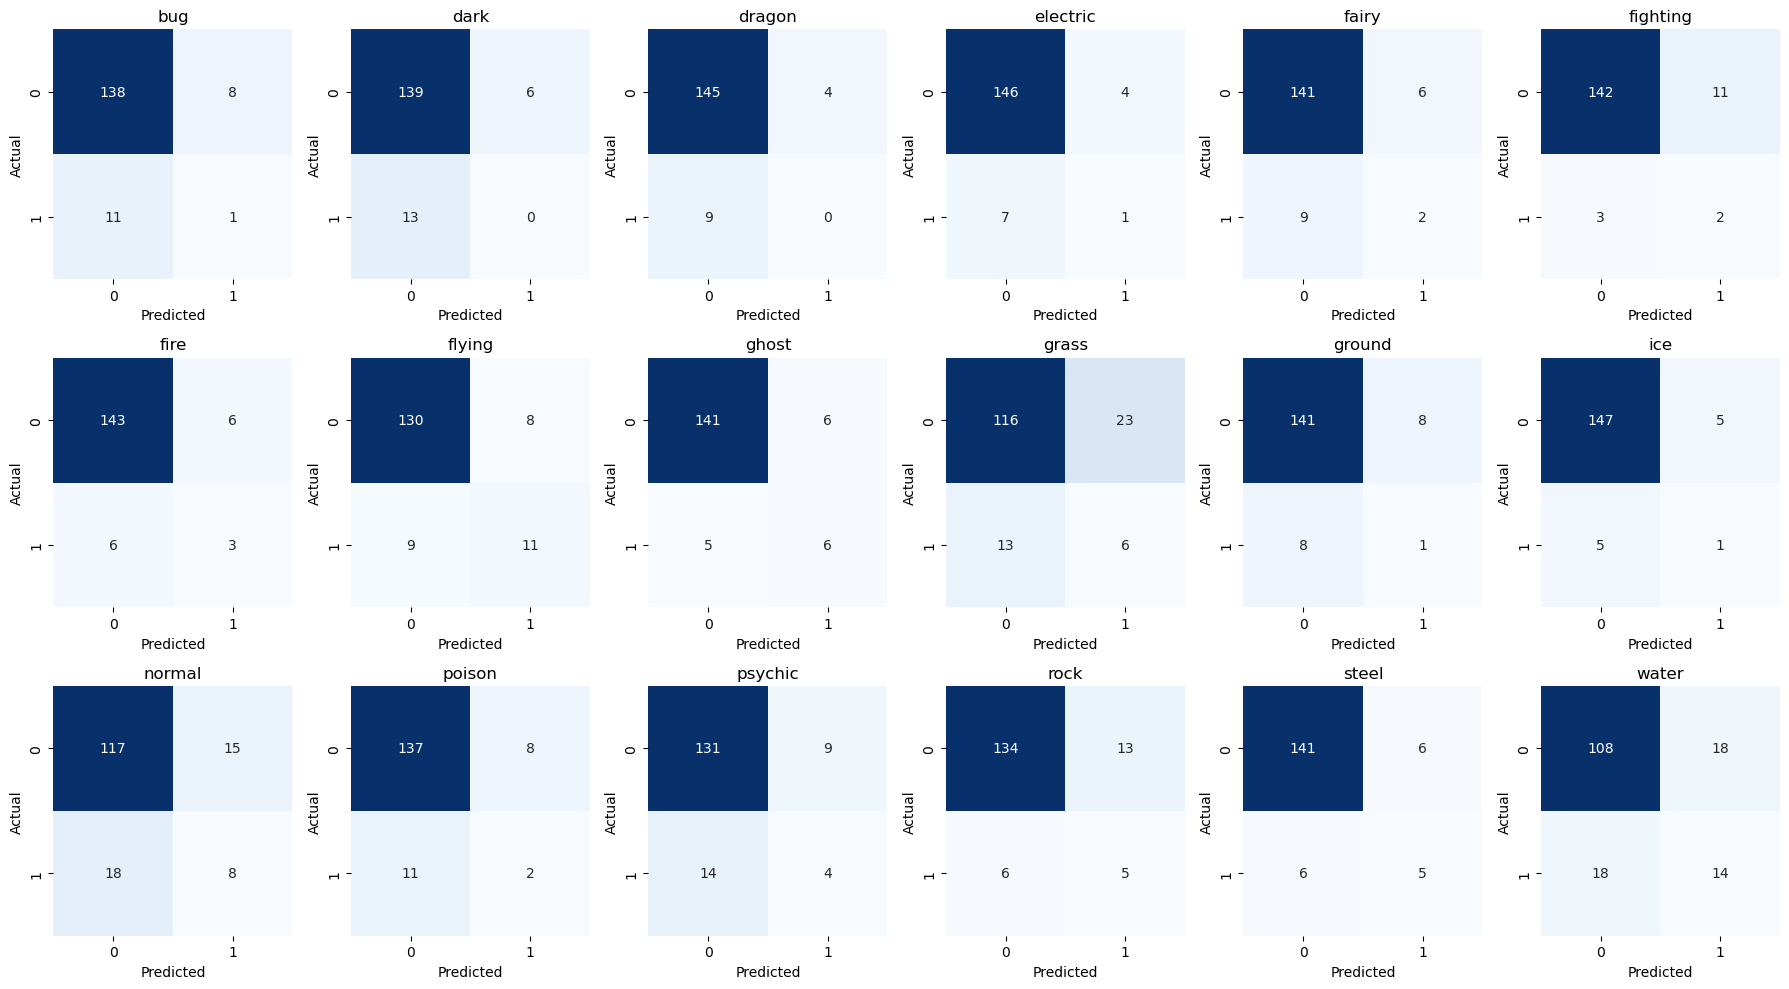

In [50]:
#confusion matrix displaying true/false positives and negatives
from sklearn.metrics import multilabel_confusion_matrix

matrices = multilabel_confusion_matrix(t_test, predictions)

fig, axes = plt.subplots(3, 6, figsize=(18, 10))

for n, ax in enumerate(axes.flatten()):
    sns.heatmap(matrices[n], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(mlb.classes_[n])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()